In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 42
SEEDS = [10, 42, 74]
tf.keras.utils.set_random_seed(SEED)

# Part A

In [2]:
(x_full, y_full), (x_clean_test, y_test) = datasets.cifar10.load_data()

y_full = y_full.flatten()
y_test = y_test.flatten()

# select 500 images - 50 per class
x_small, _, y_small, _ = train_test_split(
    x_full, y_full,
    train_size=500,
    stratify=y_full,
    random_state=SEED
)

# split into 400 training and 100 validation images
x_train, x_val, y_train, y_val = train_test_split(
    x_small, y_small,
    test_size=100,
    stratify=y_small,
    random_state=SEED
)

# normalize training and validation images
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0

print("Training:", x_train.shape)
print("Validation:", x_val.shape)

print("Training per class:", np.bincount(y_train))
print("Validation per class:", np.bincount(y_val))



170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2537s 15us/step
Training: (400, 32, 32, 3)
Validation: (100, 32, 32, 3)
Training per class: [40 40 40 40 40 40 40 40 40 40]
Validation per class: [10 10 10 10 10 10 10 10 10 10]


In [3]:
def build_baseline():
    inputs = layers.Input(shape=(32, 32, 3))

    # initial convolution
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D((2, 2))(x)

    # inception branch 1: 1×1 convolution
    branch1 = layers.Conv2D(32, (1, 1), activation="relu", padding="same")(x)

    # inception branch 2: reduction + 3×3 convolution
    branch3 = layers.Conv2D(16, (1, 1), activation="relu", padding="same")(x)
    branch3 = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(branch3)

    # inception branch 3: reduction + 5×5 convolution
    branch5 = layers.Conv2D(16, (1, 1), activation="relu", padding="same")(x)
    branch5 = layers.Conv2D(32, (5, 5), activation="relu", padding="same")(branch5)

    # combine branches
    x = layers.Concatenate()([branch1, branch3, branch5])
    x = layers.MaxPooling2D((2, 2))(x)

    # another convolution block
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # classifier
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs)

    return model

In [4]:
# checking the parameters
model = build_baseline()
model.summary()

print("Trainable parameters:", model.count_params())


I0000 00:00:1791719031.361745      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791719031.366465      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 16,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │        528 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │        528 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │      1,056 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │      4,640 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │     12,832 │ conv2d_4[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_1[0][0],   │
│ (Concatenate)       │ 96)               │            │ conv2d_3[0][0],   │
│                     │                   │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 8, 8, 96)  │          0 │ concatenate[0][0] │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 8, 8, 64)  │     55,360 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 4, 4, 64)  │          0 │ conv2d_6[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 1024)      │          0 │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     65,600 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │        650 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 142,090 (555.04 KB)

 Trainable params: 142,090 (555.04 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 142090


In [5]:
baseline_models = []
histories = []
train_scores = []
val_scores = []

for seed in SEEDS:
    print("\nSeed:", seed)

    tf.keras.utils.set_random_seed(seed)
    model = build_baseline()

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=50,
        batch_size=32,
        verbose=2
    )

    train_loss, train_acc = model.evaluate(
        x_train, y_train, verbose=1
    )
    val_loss, val_acc = model.evaluate(
        x_val, y_val, verbose=1
    )

    baseline_models.append(model)
    histories.append(history.history)
    train_scores.append(train_acc * 100)
    val_scores.append(val_acc * 100)


Seed: 10
Epoch 1/50


I0000 00:00:1791719042.181005     142 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


13/13 - 12s - 951ms/step - accuracy: 0.0825 - loss: 2.3118 - val_accuracy: 0.1000 - val_loss: 2.2958
Epoch 2/50
13/13 - 0s - 12ms/step - accuracy: 0.1550 - loss: 2.2876 - val_accuracy: 0.1100 - val_loss: 2.2831
Epoch 3/50
13/13 - 0s - 11ms/step - accuracy: 0.1750 - loss: 2.2478 - val_accuracy: 0.1500 - val_loss: 2.2490
Epoch 4/50
13/13 - 0s - 11ms/step - accuracy: 0.2075 - loss: 2.1502 - val_accuracy: 0.1900 - val_loss: 2.1921
Epoch 5/50
13/13 - 0s - 11ms/step - accuracy: 0.2450 - loss: 2.0295 - val_accuracy: 0.2500 - val_loss: 2.1509
Epoch 6/50
13/13 - 0s - 11ms/step - accuracy: 0.3200 - loss: 1.9052 - val_accuracy: 0.2500 - val_loss: 2.0594
Epoch 7/50
13/13 - 0s - 11ms/step - accuracy: 0.3200 - loss: 1.7892 - val_accuracy: 0.2900 - val_loss: 2.0320
Epoch 8/50
13/13 - 0s - 12ms/step - accuracy: 0.4125 - loss: 1.6506 - val_accuracy: 0.2600 - val_loss: 2.0480
Epoch 9/50
13/13 - 0s - 11ms/step - accuracy: 0.4525 - loss: 1.5186 - val_accuracy: 0.2800 - val_loss: 1.9872
Epoch 10/50
13/13 -

In [6]:
for i, seed in enumerate(SEEDS):
    print(
        f"Seed {seed}: "
        f"Training = {train_scores[i]:.2f}%, "
        f"Validation = {val_scores[i]:.2f}%"
    )

print(
    f"\nTraining accuracy: "
    f"{np.mean(train_scores):.2f}% ± {np.std(train_scores, ddof=1):.2f}%"
)

print(
    f"Validation accuracy: "
    f"{np.mean(val_scores):.2f}% ± {np.std(val_scores, ddof=1):.2f}%"
)

Seed 10: Training = 100.00%, Validation = 30.00%
Seed 42: Training = 100.00%, Validation = 34.00%
Seed 74: Training = 100.00%, Validation = 32.00%

Training accuracy: 100.00% ± 0.00%
Validation accuracy: 32.00% ± 2.00%


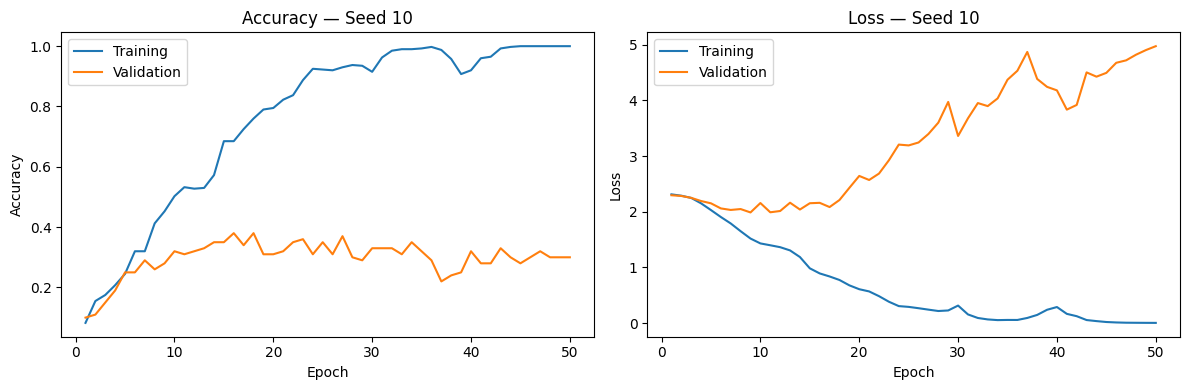

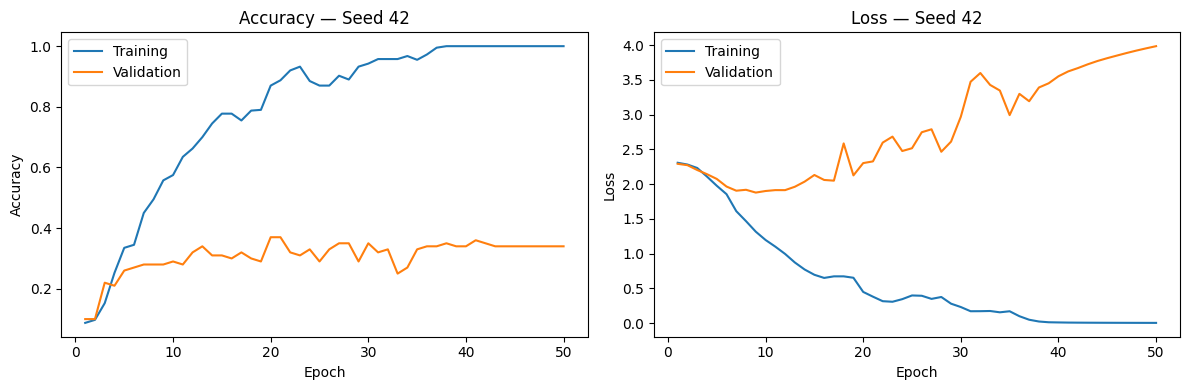

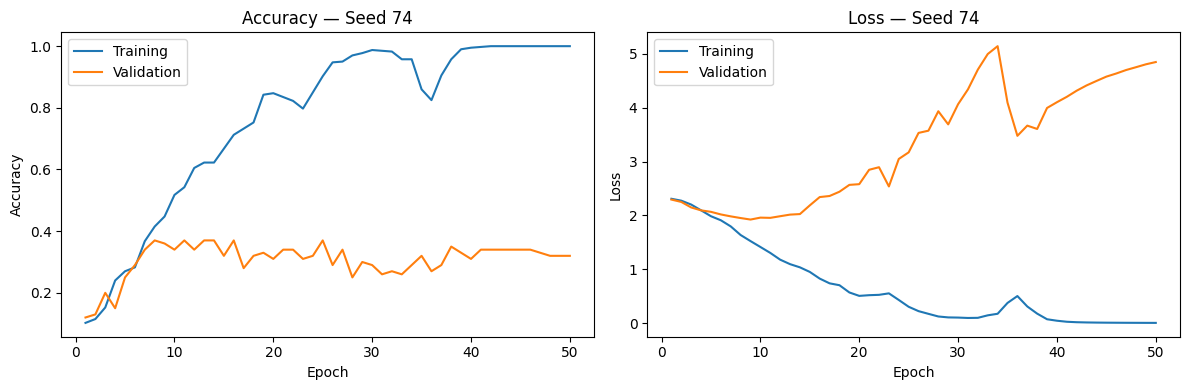

In [7]:
for i, seed in enumerate(SEEDS):
    history = histories[i]
    epochs = range(1, len(history["loss"]) + 1)

    plt.figure(figsize=(12, 4))

    # accuracy curve
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["accuracy"], label="Training")
    plt.plot(epochs, history["val_accuracy"], label="Validation")
    plt.title(f"Accuracy — Seed {seed}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # loss curve
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["loss"], label="Training")
    plt.plot(epochs, history["val_loss"], label="Validation")
    plt.title(f"Loss — Seed {seed}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [8]:
# defining corruption pipeline
from scipy.ndimage import rotate

def create_shifted_test(images):
    rng = np.random.default_rng(2026)

    # original images are uint8 with values from 0 to 255
    shifted = images.astype("float32") / 255.0

    for i in range(len(shifted)):
        image = shifted[i].copy()

        # 1. rotation
        angle = rng.uniform(-25, 25)
        image = rotate(
            image, angle,
            axes=(0, 1),
            reshape=False,
            order=1,
            mode="reflect"
        )

        # 2. contrast
        contrast = rng.uniform(0.7, 1.3)
        mean = image.mean(axis=(0, 1), keepdims=True)
        image = (image - mean) * contrast + mean

        # 3. brightness
        brightness = rng.uniform(-0.2, 0.2)
        image = np.clip(image + brightness, 0, 1)

        # 4. held-out corruption: grayscale
        if rng.random() < 0.5:
            gray = (
                0.299 * image[:, :, 0]
                + 0.587 * image[:, :, 1]
                + 0.114 * image[:, :, 2]
            )
            image = np.repeat(gray[:, :, None], 3, axis=2)

        # 5. random rectangular occlusion: about 256 of 1024 pixels
        height = int(rng.integers(12, 21))
        width = round(256 / height)

        top = int(rng.integers(0, 33 - height))
        left = int(rng.integers(0, 33 - width))

        image[top:top + height, left:left + width, :] = 0

        shifted[i] = image

    return shifted

In [9]:
# normalize the original clean test images
x_clean_eval = x_clean_test.astype("float32") / 255.0

# create the fixed corrupted test images
x_shifted_test = create_shifted_test(x_clean_test)

print("Clean test:", x_clean_eval.shape)
print("Shifted test:", x_shifted_test.shape)
print("Labels:", y_test.shape)

Clean test: (10000, 32, 32, 3)
Shifted test: (10000, 32, 32, 3)
Labels: (10000,)


In [42]:
#clean and shifted test accuracy analysis

clean_scores = []
shifted_scores = []

for i, seed in enumerate(SEEDS):
    model = baseline_models[i]

    # Evaluate each baseline on both test sets
    _, clean_acc = model.evaluate(
        x_clean_eval, y_test, verbose=0
    )

    _, shifted_acc = model.evaluate(
        x_shifted_test, y_test, verbose=0
    )

    clean_scores.append(clean_acc * 100)
    shifted_scores.append(shifted_acc * 100)

    print(
        f"Seed {seed}: "
        f"Clean test = {clean_scores[i]:.2f}%, "
        f"Shifted test = {shifted_scores[i]:.2f}%"
    )

print(
    f"\nClean-test accuracy: "
    f"{np.mean(clean_scores):.2f}% ± "
    f"{np.std(clean_scores, ddof=1):.2f}%"
)

print(
    f"Shifted-test accuracy: "
    f"{np.mean(shifted_scores):.2f}% ± "
    f"{np.std(shifted_scores, ddof=1):.2f}%"
)

gap = np.mean(clean_scores) - np.mean(shifted_scores)
print(f"\nClean–shifted accuracy gap: {gap:.2f} percentage points")

Seed 10: Clean test = 35.63%, Shifted test = 13.85%
Seed 42: Clean test = 37.31%, Shifted test = 14.84%
Seed 74: Clean test = 35.78%, Shifted test = 15.68%

Clean-test accuracy: 36.24% ± 0.93%
Shifted-test accuracy: 14.79% ± 0.92%

Clean–shifted accuracy gap: 21.45 percentage points


#### The baseline achieved 100% training accuracy but only 32.67% validation and 36.24% clean-test accuracy, indicating substantial overfitting.
#### Shifted-test accuracy fell to 14.79%, a decrease of 21.45 percentage points relative to clean-test accuracy.
#### Rotation, lighting changes, occlusion, and grayscale altered the input distribution and disrupted features learned from clean images.
#### The failure therefore reflects both overfitting to the small training set and poor robustness to covariate shift.

# Part B

| Group | Chosen augmentation | Justification |
|---|---|---|
| Geometric | Pad by 4 pixels, then randomly crop to 32×32 | Handles changes in object position |
| Geometric | Horizontal flip | Objects can plausibly face either direction |
| Geometric | Rotation within ±25° | Handles moderate changes in orientation |
| Photometric | Brightness ±0.15; contrast and saturation ×0.8–1.2 | Reduces dependence on lighting and color intensity |
| Photometric | Occasional mild blur and Gaussian noise | Encourages recognition despite degraded image detail |
| Occlusion | Occasional 10×10 Cutout | Encourages use of multiple object parts |
| Mixing | Mixup with `alpha=0.2` | Reduces memorization by mixing images and their labels |

In [10]:
def make_geometric_augmentation(seed):
    return models.Sequential([
        layers.ZeroPadding2D(padding=4),
        layers.RandomCrop(32, 32, seed=seed),
        layers.RandomFlip("horizontal", seed=seed + 1),
        layers.RandomRotation(factor=25 / 360, fill_mode="reflect", seed=seed + 2)
    ])

geometric_augmentation = make_geometric_augmentation(SEED)

In [11]:
def photometric_augmentation(image):
    # change lighting and color intensity
    image = tf.image.random_brightness(image, max_delta=0.15)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)

    image = tf.clip_by_value(image, 0, 1)

    # apply a mild 3×3 average blur with 30% probability
    if tf.random.uniform(()) < 0.3:
        image = tf.nn.avg_pool2d(image[None, ...], ksize=3,strides=1, padding="SAME")[0]

    # ddd Gaussian noise with 30% probability
    if tf.random.uniform(()) < 0.3:
        noise = tf.random.normal(tf.shape(image),mean=0.0,stddev=0.03)
        image = image + noise

    return tf.clip_by_value(image, 0, 1)

In [12]:
def cutout(image):
    # apply Cutout with 50% probability
    if tf.random.uniform(()) < 0.5:
        size = 10

        top = tf.random.uniform((), minval=0, maxval=23, dtype=tf.int32)
        left = tf.random.uniform((), minval=0, maxval=23, dtype=tf.int32)

        # zero inside the square, one everywhere else
        mask = tf.pad(
            tf.zeros((size, size, 3)),
            paddings=[
                [top, 32 - size - top],
                [left, 32 - size - left],
                [0, 0]
            ],
            constant_values=1
        )

        image = image * mask

    return image

In [13]:
def mixup(images, labels, alpha=0.2):
    # convert integer labels into 10-class vectors
    labels = tf.one_hot(labels, depth=10)

    # randomly pair the images in this batch
    indices = tf.random.shuffle(tf.range(tf.shape(images)[0]))

    # sample a mixing weight from a Beta distribution
    a = tf.random.gamma([], alpha)
    b = tf.random.gamma([], alpha)
    weight = a / (a + b + 1e-7)

    mixed_images = (weight * images + (1 - weight) * tf.gather(images, indices))

    mixed_labels = (weight * labels + (1 - weight) * tf.gather(labels, indices))

    return mixed_images, mixed_labels

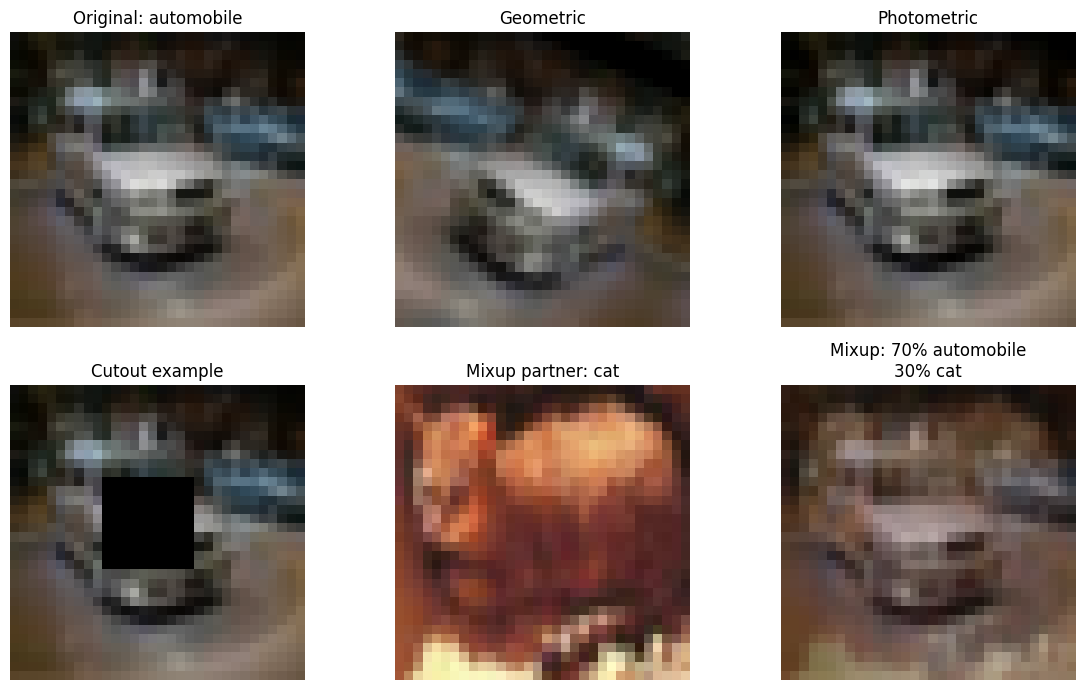

In [14]:
#just checking out augmented images, training data not being modified

# first training image
image = tf.convert_to_tensor(x_train[0])

# geometric augmentation
geometric = geometric_augmentation(image[None, ...], training=True)[0]

# photometric augmentation
photometric = photometric_augmentation(image)

# fixed Cutout example for display
cutout_example = x_train[0].copy()
cutout_example[10:20, 10:20, :] = 0

# choose a second image from a different class
second_index = np.where(y_train != y_train[0])[0][0]
second_image = x_train[second_index]

# fixed Mixup example: 70% first image + 30% second image (just for ilustration percentage speicified, otherwise random)
mixed_image = 0.7 * x_train[0] + 0.3 * second_image

class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

first_class = class_names[y_train[0]]
second_class = class_names[y_train[second_index]]

examples = [image, geometric, photometric, cutout_example, second_image, mixed_image]

titles = [
    f"Original: {first_class}",
    "Geometric",
    "Photometric",
    "Cutout example",
    f"Mixup partner: {second_class}",
    f"Mixup: 70% {first_class}\n30% {second_class}"
]

plt.figure(figsize=(12, 7))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(examples[i])
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

#### Would vertical flip help or hurt? Why?
Vertical flipping would likely hurt overall because many CIFAR-10 objects, such as cars, ships, and horses, usually appear upright. Upside-down examples introduce less realistic variation and may remove useful orientation cues. Horizontal flipping is a more plausible transformation.

#### What is the trade-off of training with ±90° rotation when the test uses ±25°?
Larger rotations encourage broader orientation robustness, but also introduce less realistic views and more loss of image content through cropping and interpolation. With limited training data and model capacity, this can reduce accuracy on ordinary images. Moderate rotation is our starting choice, with any adjustments guided by validation results.

#### Why can too much augmentation reduce accuracy in a small model?
Excessive augmentation can hide or distort the features needed to recognize the class. A small model may struggle to learn across that much variation within the available training budget, causing underfitting. Combining strong augmentation with other regularization can also make learning unnecessarily difficult.

# Part C

In [27]:
def build_regularized_model():
    inputs = layers.Input(shape=(32, 32, 3))

    # initial convolution
    x = layers.Conv2D(32, (3, 3), padding="same", use_bias=False)(inputs)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # inception branch 1: 1×1
    branch1 = layers.Conv2D(32, (1, 1), padding="same", use_bias=False)(x)
    branch1 = layers.BatchNormalization(momentum=0.9)(branch1)
    branch1 = layers.Activation("relu")(branch1)

    # inception branch 2: reduction + 3×3
    branch3 = layers.Conv2D(16, (1, 1), padding="same", use_bias=False)(x)
    branch3 = layers.BatchNormalization(momentum=0.9)(branch3)
    branch3 = layers.Activation("relu")(branch3)

    branch3 = layers.Conv2D(32, (3, 3), padding="same", use_bias=False)(branch3)
    branch3 = layers.BatchNormalization(momentum=0.9)(branch3)
    branch3 = layers.Activation("relu")(branch3)

    # inception branch 3: reduction + 5×5
    branch5 = layers.Conv2D(16, (1, 1), padding="same", use_bias=False)(x)
    branch5 = layers.BatchNormalization(momentum=0.9)(branch5)
    branch5 = layers.Activation("relu")(branch5)

    branch5 = layers.Conv2D(32, (5, 5), padding="same", use_bias=False)(branch5)
    branch5 = layers.BatchNormalization(momentum=0.9)(branch5)
    branch5 = layers.Activation("relu")(branch5)

    # combine branches
    x = layers.Concatenate()([branch1, branch3, branch5])
    x = layers.MaxPooling2D((2, 2))(x)

    # another convolution
    x = layers.Conv2D(64, (3, 3), padding="same", use_bias=False)(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # hidden Dense layer
    x = layers.Flatten()(x)
    x = layers.Dense(64, use_bias=False)(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.3)(x)

    # output layer
    outputs = layers.Dense(10, activation="softmax")(x)

    return models.Model(inputs, outputs)

In [28]:
# weight decay and label smoothing
def compile_regularized_model(model, smoothing=0.0):
    model.compile(
        optimizer=tf.keras.optimizers.AdamW(
            learning_rate=0.001,
            weight_decay=0.0001
        ),
        loss=tf.keras.losses.CategoricalCrossentropy(
            label_smoothing=smoothing
        ),
        metrics=["accuracy"]
    )

In [17]:
# learning rate schedule
def learning_rate_schedule(epoch):
    if epoch < 25:
        return 0.001
    elif epoch < 40:
        return 0.0003
    else:
        return 0.0001

In [33]:
# early stopping and scheduling callbacks
def make_callbacks():
    lr_callback = tf.keras.callbacks.LearningRateScheduler(
        learning_rate_schedule
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    )

    return [lr_callback, early_stop]

In [19]:
#checking model and parameter count
tf.keras.utils.set_random_seed(SEED)

regularized_model = build_regularized_model()
regularized_model.summary()

trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in regularized_model.trainable_weights
)

print("Trainable parameters:", trainable_params)

assert trainable_params <= 1_000_000

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 32, 32,    │        864 │ input_layer_5[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d_28[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_12    │ (None, 16, 16,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 16, 16,    │        512 │ max_pooling2d_12… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 16, 16,    │        512 │ max_pooling2d_12… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │         64 │ conv2d_30[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │         64 │ conv2d_32[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 16, 16,    │      1,024 │ max_pooling2d_12… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 16, 16,    │      4,608 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 16, 16,    │     12,800 │ activation_4[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_29[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_31[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_33[0][0] 

 Total params: 142,954 (558.41 KB)

 Trainable params: 142,378 (556.16 KB)

 Non-trainable params: 576 (2.25 KB)

Trainable parameters: 142378


| Technique | Placement in our implementation | Justification |
|---|---|---|
| **BatchNorm** | After every convolution, including Inception branches, and the hidden Dense layer, before ReLU | Normalizes intermediate activations before the nonlinearity, supporting stable optimization throughout the network. |
| **Dropout (0.3)** | After the hidden Dense layer’s BatchNorm and ReLU, before the output layer | Discourages reliance on particular high-level classifier features. We leave early convolutional features intact rather than randomly disrupting low-level edge and texture extraction. This is a design choice, not a rule prohibiting convolutional dropout. |
| **Weight decay** | In the AdamW optimizer, during parameter updates | Discourages excessive parameter growth across the network. It is an optimizer setting, so it is not placed between layers. |
| **Learning-rate scheduling** | At the beginning of each epoch through a callback | Allows larger updates early and smaller adjustments later. It controls optimization rather than modifying activations. |
| **Early stopping** | Checks validation loss after each epoch | Stops training after 10 epochs without improvement and restores the best validation-loss weights, limiting unnecessary training once generalization stops improving. |
| **Label smoothing** | In categorical cross-entropy, enabled for the specified configuration | Softens targets during loss calculation to discourage overconfidence. It belongs in the loss, not as a layer after softmax. |

# Part D

In [34]:
# listing confirgutations - name, geometric, photometric, cutout, mixup

configurations = [
    ("No augmentation", False, False, False, False),
    ("Geometric only", True, False, False, False),
    ("Photometric only", False, True, False, False),
    ("Geometric + photometric", True, True, False, False),
    ("+ Cutout", True, True, True, False),
    ("+ Mixup + label smoothing", True, True, True, True)
]

In [35]:
# building training data pipeline

def make_training_data(seed, use_geo, use_photo, use_cutout, use_mixup):

    geometric = make_geometric_augmentation(seed)

    # transform one image at a time
    def augment_image(image, label):
        if use_geo:
            image = geometric(image[None, ...], training=True)[0]

        if use_photo:
            image = photometric_augmentation(image)

        if use_cutout:
            image = cutout(image)

        return image, label

    # used when Mixup is disabled
    def encode_labels(images, labels):
        return images, tf.one_hot(labels, depth=10)

    data = tf.data.Dataset.from_tensor_slices((x_train, y_train))

    data = data.shuffle(buffer_size=len(x_train), seed=seed, reshuffle_each_iteration=True)

    data = data.map(augment_image)
    data = data.batch(32)

    if use_mixup:
        data = data.map(mixup)
    else:
        data = data.map(encode_labels)

    return data

In [36]:
#prepare validation labels
y_val_onehot = tf.keras.utils.to_categorical(
    y_val, num_classes=10
)

In [37]:
#train the configurations
results = {}

for name, use_geo, use_photo, use_cutout, use_mixup in configurations:
    print("\nConfiguration:", name)

    saved_models = []
    saved_histories = []
    val_scores = []

    for seed in SEEDS:
        print("Seed:", seed)

        tf.keras.utils.set_random_seed(seed)

        # fresh model for every run
        model = build_regularized_model()

        # smoothing is enabled only in the specified row
        smoothing = 0.05 if use_mixup else 0.0
        compile_regularized_model(model, smoothing=smoothing)

        train_data = make_training_data(
            seed,
            use_geo,
            use_photo,
            use_cutout,
            use_mixup
        )

        history = model.fit(
            train_data,
            validation_data=(x_val, y_val_onehot),
            epochs=50,
            callbacks=make_callbacks(),
            verbose=1
        )

        # early stopping has restored the best validation-loss weights
        _, val_acc = model.evaluate(x_val, y_val_onehot, verbose=0)

        saved_models.append(model)
        saved_histories.append(history.history)
        val_scores.append(val_acc * 100)

    results[name] = {
        "models": saved_models,
        "histories": saved_histories,
        "val_scores": val_scores
    }

    print(
        f"{name}: "
        f"{np.mean(val_scores):.2f}% ± "
        f"{np.std(val_scores, ddof=1):.2f}%"
    )


Configuration: No augmentation
Seed: 10
Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 446ms/step - accuracy: 0.1775 - loss: 2.4417 - val_accuracy: 0.1100 - val_loss: 2.5887 - learning_rate: 0.0010
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4300 - loss: 1.6672 - val_accuracy: 0.1000 - val_loss: 2.7178 - learning_rate: 0.0010
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5625 - loss: 1.3276 - val_accuracy: 0.1500 - val_loss: 2.5283 - learning_rate: 0.0010
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7150 - loss: 1.0682 - val_accuracy: 0.2700 - val_loss: 2.1328 - learning_rate: 0.0010
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7850 - loss: 0.8766 - val_accuracy: 0.3600 - val_loss: 1.9427 - learning_rate: 0.0010
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8875 - loss: 0.6881 - val_accuracy: 0.4600 - val_loss: 1.7733 - learning_rate: 0.0010
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step 

In [38]:
#validation comparison
for name in results:
    scores = results[name]["val_scores"]

    print(
        f"{name}: "
        f"{np.mean(scores):.2f}% ± "
        f"{np.std(scores, ddof=1):.2f}%"
    )

No augmentation: 43.67% ± 4.93%
Geometric only: 40.67% ± 4.16%
Photometric only: 39.67% ± 2.08%
Geometric + photometric: 45.00% ± 2.00%
+ Cutout: 43.00% ± 3.61%
+ Mixup + label smoothing: 43.00% ± 3.46%


In [39]:
#selecting final configuration using validation
best_name = None
best_mean = -1

for name in results:
    mean_accuracy = np.mean(results[name]["val_scores"])

    if mean_accuracy > best_mean:
        best_mean = mean_accuracy
        best_name = name

final_models = results[best_name]["models"]

print("Selected configuration:", best_name)
print("Mean validation accuracy:", best_mean)

Selected configuration: Geometric + photometric
Mean validation accuracy: 44.99999980131785


Geometric + photometric is the validation-selected configuration because it gives the highest accuracy on the validation data.

In [40]:
#running on test data
for name in results:
    clean_scores = []
    shifted_scores = []
    clean_predictions = []
    shifted_predictions = []

    for model in results[name]["models"]:
        # predict class probabilities
        clean_probs = model.predict(x_clean_eval, batch_size=128, verbose=0)

        shifted_probs = model.predict(x_shifted_test, batch_size=128, verbose=0)

        # select the class with the highest probability
        clean_pred = np.argmax(clean_probs, axis=1)
        shifted_pred = np.argmax(shifted_probs, axis=1)

        # calculate accuracy as a percentage
        clean_scores.append(np.mean(clean_pred == y_test) * 100)
        shifted_scores.append(np.mean(shifted_pred == y_test) * 100)

        clean_predictions.append(clean_pred)
        shifted_predictions.append(shifted_pred)

    results[name]["clean_scores"] = clean_scores
    results[name]["shifted_scores"] = shifted_scores
    results[name]["clean_predictions"] = clean_predictions
    results[name]["shifted_predictions"] = shifted_predictions

    print("Evaluated:", name)

Evaluated: No augmentation
Evaluated: Geometric only
Evaluated: Photometric only
Evaluated: Geometric + photometric
Evaluated: + Cutout
Evaluated: + Mixup + label smoothing


In [41]:
import pandas as pd

def mean_std(scores):
    return (
        f"{np.mean(scores):.2f}% ± "
        f"{np.std(scores, ddof=1):.2f}%"
    )

rows = []

for name in results:
    rows.append({
        "Configuration": name,
        "Val Acc": mean_std(results[name]["val_scores"]),
        "Clean Test": mean_std(results[name]["clean_scores"]),
        "Shifted Test": mean_std(results[name]["shifted_scores"])
    })

# final row repeats the validation-selected configuration
rows.append({
    "Configuration": "Final model: " + best_name,
    "Val Acc": mean_std(results[best_name]["val_scores"]),
    "Clean Test": mean_std(results[best_name]["clean_scores"]),
    "Shifted Test": mean_std(results[best_name]["shifted_scores"])
})

ablation_table = pd.DataFrame(rows)
display(ablation_table)

,Configuration,Val Acc,Clean Test,Shifted Test
0,No augmentation,43.67% ± 4.93%,36.94% ± 1.44%,17.76% ± 0.40%
1,Geometric only,40.67% ± 4.16%,39.83% ± 3.60%,20.42% ± 0.92%
2,Photometric only,39.67% ± 2.08%,38.37% ± 1.22%,18.45% ± 0.71%
3,Geometric + photometric,45.00% ± 2.00%,42.72% ± 0.12%,22.61% ± 0.92%
4,+ Cutout,43.00% ± 3.61%,41.15% ± 1.30%,27.26% ± 0.46%
5,+ Mixup + label smoothing,43.00% ± 3.46%,40.62% ± 1.20%,27.20% ± 0.52%
6,Final model: Geometric + photometric,45.00% ± 2.00%,42.72% ± 0.12%,22.61% ± 0.92%


Cutout gave the largest incremental shifted-test gain. This is consistent with the test’s rectangular occlusion: training with missing image regions encourages recognition from the remaining visible features. The combined corruption test supports this explanation, but does not isolate occlusion’s individual effect.

# Part E

In [43]:
#saved prediction

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# three prediction arrays: one for each seed
final_predictions = results[best_name]["shifted_predictions"]

print("Configuration:", best_name)
print("Number of seed runs:", len(final_predictions))

Configuration: Geometric + photometric
Number of seed runs: 3


In [44]:
#accuracy for each class
class_scores = []

for predictions in final_predictions:
    seed_scores = []

    for class_id in range(10):
        # Select test images whose true label is this class
        mask = (y_test == class_id)

        accuracy = np.mean(predictions[mask] == y_test[mask]) * 100

        seed_scores.append(accuracy)

    class_scores.append(seed_scores)

class_scores = np.array(class_scores)

class_table = pd.DataFrame({
    "Class": class_names,
    "Mean accuracy (%)": class_scores.mean(axis=0),
    "Std (percentage points)": class_scores.std(axis=0, ddof=1)
})

display(class_table.round(2))

,Class,Mean accuracy (%),Std (percentage points)
0,airplane,36.10,2.62
1,automobile,25.17,5.61
2,bird,39.73,6.23
3,cat,24.80,3.03
4,deer,3.33,0.15
5,dog,15.50,1.61
6,frog,5.33,3.46
7,horse,15.10,8.23
8,ship,23.17,4.40
9,truck,37.90,7.66


Per-class accuracy was calculated on the shifted test set and reported as mean ± sample standard deviation across three training seeds. Bird had the highest recall at 39.73% ± 6.23%, followed by truck at 37.90% ± 7.66% and airplane at 36.10% ± 2.62%. Deer and frog had the lowest recall, at 3.33% ± 0.15% and 5.33% ± 3.46%, respectively. These results show that robustness varies considerably across classes. Bird’s relatively high recall does not necessarily indicate reliable bird classification, because many non-bird images were also predicted as bird.

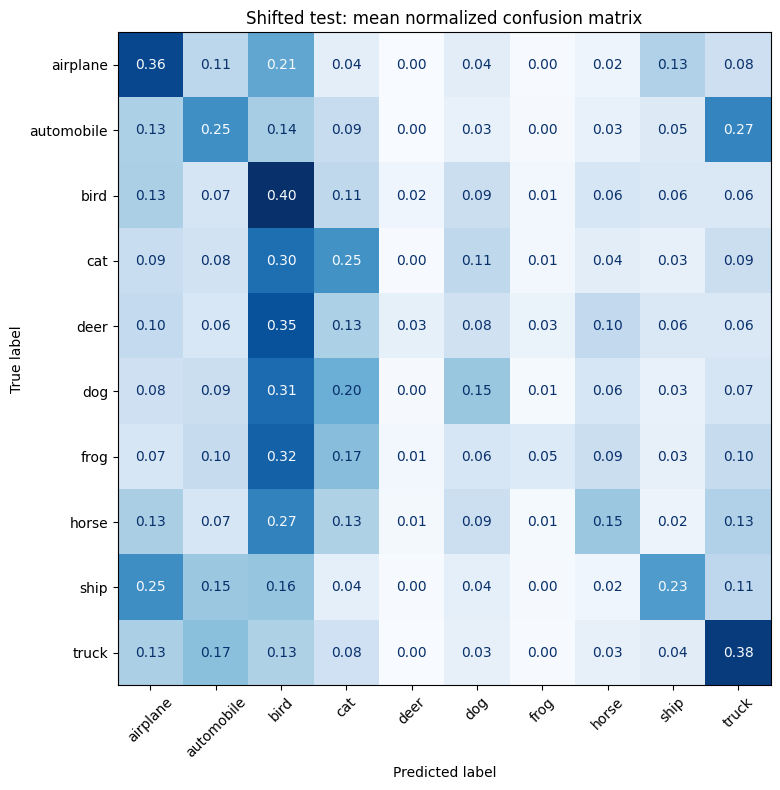

In [45]:
#confusion matrix
matrices = []

for predictions in final_predictions:
    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=range(10),
        normalize="true"
    )

    matrices.append(matrix)

# average the normalized matrices across the three seeds
mean_matrix = np.mean(matrices, axis=0)

fig, ax = plt.subplots(figsize=(10, 8))

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=mean_matrix,
    display_labels=class_names
)

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Shifted test: mean normalized confusion matrix")
plt.tight_layout()
plt.show()

The confusion matrix is normalized by true class and averaged across the three seeds. Each row represents the actual class, and each column represents the predicted class. Diagonal entries represent correct predictions, while off-diagonal entries represent errors. The bird column contains substantial errors from several classes, indicating a tendency to predict bird under corruption. Predictions of deer and frog are comparatively rare.

In [46]:
2.

# remove correct predictions from consideration
errors = mean_matrix.copy()
np.fill_diagonal(errors, 0)

# get the five largest off-diagonal entries
top_indices = np.argsort(errors.flatten())[-5:][::-1]

for index in top_indices:
    actual, predicted = np.unravel_index(index, errors.shape)

    print(
        f"{class_names[actual]} → {class_names[predicted]}: "
        f"{errors[actual, predicted] * 100:.2f}%"
    )

deer → bird: 34.60%
frog → bird: 32.17%
dog → bird: 30.67%
cat → bird: 30.23%
horse → bird: 27.13%


The largest directional confusion was deer → bird (34.60%), followed by frog → bird (32.17%), dog → bird (30.67%), cat → bird (30.23%), and horse → bird (27.13%). Occlusion can hide distinctive body parts, rotation changes apparent orientation, and grayscale removes color information. At CIFAR-10’s low resolution, the remaining animal shapes and background textures may be difficult to distinguish. These are plausible explanations; the confusion matrix alone does not establish the exact features responsible for the errors.

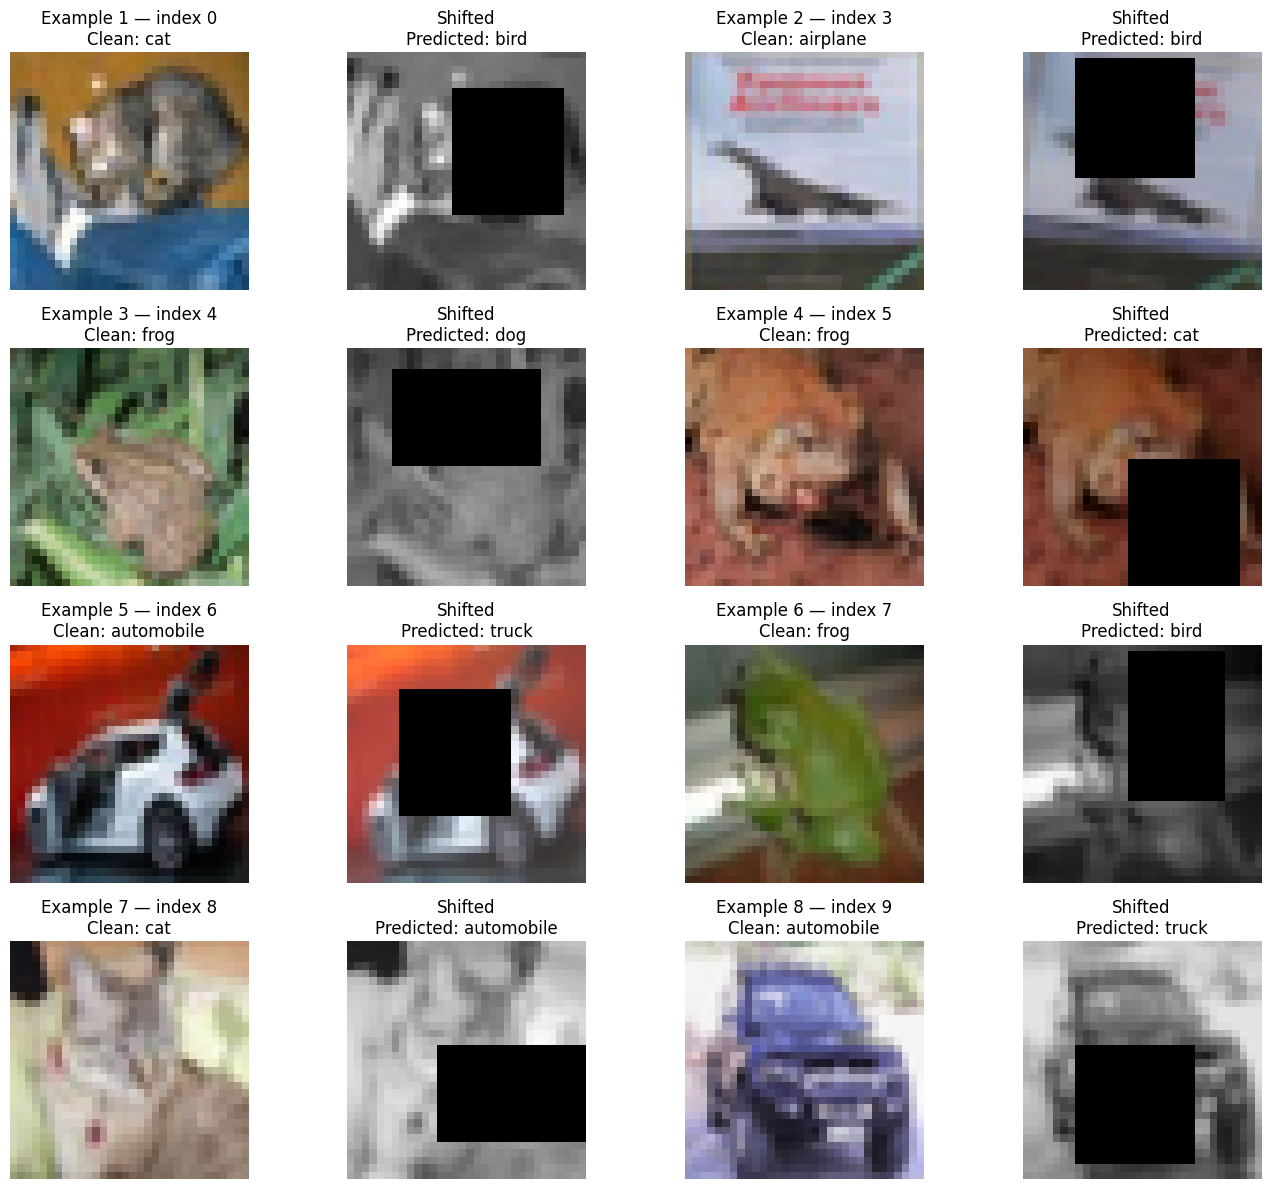

In [47]:
3.
#displaying misclassified images

# use the first seed's saved predictions
example_predictions = final_predictions[0]

# find incorrectly classified images
wrong_indices = np.where(example_predictions != y_test)[0]
selected_indices = wrong_indices[:8]

fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for i, index in enumerate(selected_indices):
    row = i // 2
    col = (i % 2) * 2

    true_name = class_names[y_test[index]]
    predicted_name = class_names[example_predictions[index]]

    # original image
    axes[row, col].imshow(x_clean_eval[index])
    axes[row, col].set_title(
        f"Example {i + 1} — index {index}\n"
        f"Clean: {true_name}"
    )
    axes[row, col].axis("off")

    # Corrupted version of the same image
    axes[row, col + 1].imshow(x_shifted_test[index])
    axes[row, col + 1].set_title(f"Shifted\nPredicted: {predicted_name}")
    axes[row, col + 1].axis("off")

plt.tight_layout()
plt.show()

The first eight shifted-test errors from the final configuration’s seed-10 model were inspected alongside their clean counterparts. The observations below identify visible properties that may have contributed to each failure. They do not prove the model’s internal reasoning or establish that each clean counterpart was classified correctly.

| Example / test index | Actual → predicted | Plausible visual explanation |
|---|---|---|
| 1 / 0 | Cat → bird | Grayscale removes color information, while the central-right occlusion hides much of the cat. The remaining partial outline provides limited evidence of the complete animal. |
| 2 / 3 | Airplane → bird | The upper-central rectangle obscures part of the aircraft’s silhouette. The remaining small, dark shape may be difficult to distinguish from another winged object. |
| 3 / 4 | Frog → dog | Grayscale removes color cues, and the upper-central occlusion hides part of the frog and its surroundings. Distinctive body and limb details are difficult to resolve. |
| 4 / 5 | Frog → cat | The lower-right rectangle hides part of the body and limbs. The remaining brown head/body region lacks a clear frog silhouette. |
| 5 / 6 | Automobile → truck | Central occlusion hides much of the windshield and body structure. The remaining vehicle features, such as wheels and metallic edges, are shared by cars and trucks. |
| 6 / 7 | Frog → bird | Grayscale removes the frog’s green color, and the tall rectangle covers much of its right side, leaving a partial outline. |
| 7 / 8 | Cat → automobile | Grayscale and lower-central occlusion remove much of the body information. Some facial detail remains, but the model fails to use it reliably; the predicted class has no obvious semantic similarity. |
| 8 / 9 | Automobile → truck | The rectangle covers the lower-front region, while grayscale removes color cues. The remaining upright, boxy shape contains features shared by cars and trucks. |

In [48]:
#4.
#grayscale only test set

# x_clean_eval is already normalized to [0, 1]
gray = (
    0.299 * x_clean_eval[:, :, :, 0]
    + 0.587 * x_clean_eval[:, :, :, 1]
    + 0.114 * x_clean_eval[:, :, :, 2]
)

# repeat grayscale values across three channels
# because the network expects RGB-shaped input
x_gray_test = np.repeat(gray[:, :, :, None], 3, axis=3)

print("Grayscale test shape:", x_gray_test.shape)

Grayscale test shape: (10000, 32, 32, 3)


Grayscale conversion was selected as the corruption held out from training. To evaluate its effect separately, all 10,000 clean test images were converted to grayscale without rotation, lighting changes, or occlusion. The grayscale channel was repeated three times to preserve the network’s required input shape. Unlike the combined shifted set, where approximately 50% of images received grayscale conversion, this isolated test converted every image. The trained models were kept frozen.

In [49]:
#evaluate models
gray_scores = []

for seed, model in zip(SEEDS, final_models):
    probabilities = model.predict(x_gray_test, batch_size=128, verbose=1)

    predictions = np.argmax(probabilities, axis=1)
    accuracy = np.mean(predictions == y_test) * 100

    gray_scores.append(accuracy)

    print(f"Seed {seed}: Grayscale accuracy = {accuracy:.2f}%")

print(
    f"\nGrayscale-only accuracy: "
    f"{np.mean(gray_scores):.2f}% ± "
    f"{np.std(gray_scores, ddof=1):.2f}%"
)

# reuse the previously calculated clean-test scores
clean_final_scores = results[best_name]["clean_scores"]

drop = np.mean(clean_final_scores) - np.mean(gray_scores)

print(f"Clean-test accuracy: {np.mean(clean_final_scores):.2f}%")
print(f"Accuracy drop from grayscale: {drop:.2f} percentage points")

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Seed 10: Grayscale accuracy = 30.72%
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Seed 42: Grayscale accuracy = 34.10%
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Seed 74: Grayscale accuracy = 32.83%

Grayscale-only accuracy: 32.55% ± 1.71%
Clean-test accuracy: 42.72%
Accuracy drop from grayscale: 10.17 percentage points


Grayscale-only accuracy was 32.55% ± 1.71%, compared with clean-test accuracy of 42.72% ± 0.12%. Removing color therefore reduced accuracy by 10.17 percentage points. The model retained approximately 76% of its clean-test accuracy, suggesting partial generalization through remaining shape, texture, and brightness information, but substantial sensitivity to color removal.
Explicit grayscale augmentation was not used during training, although saturation jitter provided related color variation. The results suggest limited robustness to the held-out corruption rather than complete color invariance. They do not establish that augmentation caused this robustness, because a controlled grayscale comparison against a model trained without augmentation was not performed. Since we implemented grayscale ourselves, it was held out from training rather than genuinely hidden from the experimenter.

# Part F

In [52]:
#define test time transformations

import time

# shift an image horizontally without wrapping pixels around.
# newly exposed pixels are filled with zeros.

def shift_horizontal(images, shift):
    shifted = np.zeros_like(images)

    if shift < 0:
        shifted[:, :, :shift, :] = images[:, :, -shift:, :]
    elif shift > 0:
        shifted[:, :, shift:, :] = images[:, :, :-shift, :]
    else:
        shifted = images.copy()

    return shifted


def make_tta_views(images):
    """
    Generate four deterministic views of each image:
    1. Original
    2. Horizontal flip
    3. Shift one pixel left
    4. Shift one pixel right
    """

    original = images
    flipped = images[:, :, ::-1, :].copy()
    shifted_left = shift_horizontal(images, -1)
    shifted_right = shift_horizontal(images, 1)

    return [
        original,
        flipped,
        shifted_left,
        shifted_right
    ]


print("Number of TTA views:", 4)

Number of TTA views: 4


In [53]:
# predict by averaging softmax probabilities
def predict_with_tta(model, images, batch_size=128):
    """
    Predict using four views of each image.
    Average their softmax probabilities.
    Return the final class predictions and averaged probabilities.
    """

    views = make_tta_views(images)

    probability_sum = None

    for view in views:
        probabilities = model.predict(
            view,
            batch_size=batch_size,
            verbose=0
        )

        if probability_sum is None:
            probability_sum = probabilities
        else:
            probability_sum += probabilities

    # average probabilities across the four views
    averaged_probabilities = probability_sum / len(views)

    # choose the class with the highest average probability
    predictions = np.argmax(averaged_probabilities, axis=1)

    return predictions, averaged_probabilities

In [54]:
#compare ordinary inference against TTA

# evaluate the validation-selected final models.
# use the same shifted images and labels as in Part E.

tta_results = []

for seed, model in zip(SEEDS, final_models):

    print(f"\nSeed: {seed}")

    # ordinary prediction: one view per image
    start_time = time.perf_counter()

    ordinary_probabilities = model.predict(
        x_shifted_test,
        batch_size=128,
        verbose=0
    )

    ordinary_predictions = np.argmax(
        ordinary_probabilities,
        axis=1
    )

    ordinary_time = time.perf_counter() - start_time

    ordinary_accuracy = (
        np.mean(ordinary_predictions == y_test) * 100
    )

    # TTA prediction: four views per image
    start_time = time.perf_counter()

    tta_predictions, tta_probabilities = predict_with_tta(
        model,
        x_shifted_test,
        batch_size=128
    )

    tta_time = time.perf_counter() - start_time

    tta_accuracy = (
        np.mean(tta_predictions == y_test) * 100
    )

    accuracy_change = tta_accuracy - ordinary_accuracy

    tta_results.append({
        "Seed": seed,
        "Ordinary accuracy (%)": ordinary_accuracy,
        "TTA accuracy (%)": tta_accuracy,
        "Change (percentage points)": accuracy_change,
        "Ordinary time (seconds)": ordinary_time,
        "TTA time (seconds)": tta_time,
        "TTA predictions": tta_predictions
    })

    print(f"Ordinary accuracy: {ordinary_accuracy:.2f}%")
    print(f"TTA accuracy:      {tta_accuracy:.2f}%")
    print(f"Accuracy change:   {accuracy_change:+.2f} percentage points")
    print(f"Ordinary time:     {ordinary_time:.2f} seconds")
    print(f"TTA time:          {tta_time:.2f} seconds")


Seed: 10
Ordinary accuracy: 22.99%
TTA accuracy:      23.66%
Accuracy change:   +0.67 percentage points
Ordinary time:     0.72 seconds
TTA time:          2.88 seconds

Seed: 42
Ordinary accuracy: 21.56%
TTA accuracy:      22.00%
Accuracy change:   +0.44 percentage points
Ordinary time:     0.68 seconds
TTA time:          2.83 seconds

Seed: 74
Ordinary accuracy: 23.29%
TTA accuracy:      24.18%
Accuracy change:   +0.89 percentage points
Ordinary time:     0.66 seconds
TTA time:          2.85 seconds


In [55]:
import pandas as pd

tta_table = pd.DataFrame([
    {
        "Seed": result["Seed"],
        "Ordinary accuracy (%)": result["Ordinary accuracy (%)"],
        "TTA accuracy (%)": result["TTA accuracy (%)"],
        "Change (pp)": result["Change (percentage points)"],
        "Ordinary time (s)": result["Ordinary time (seconds)"],
        "TTA time (s)": result["TTA time (seconds)"]
    }
    for result in tta_results
])

display(tta_table.round(2))


# mean and sample standard deviation across the three seeds

for column in [
    "Ordinary accuracy (%)",
    "TTA accuracy (%)",
    "Change (pp)",
    "Ordinary time (s)",
    "TTA time (s)"
]:
    values = tta_table[column]

    print(
        f"{column}: "
        f"{values.mean():.2f} ± {values.std(ddof=1):.2f}"
    )


# calculate the average inference-time multiplier

time_ratio = (
    tta_table["TTA time (s)"].mean()
    / tta_table["Ordinary time (s)"].mean()
)

print(f"\nInference-time multiplier: {time_ratio:.2f}x")
print("Number of views per image: 4")

,Seed,Ordinary accuracy (%),TTA accuracy (%),Change (pp),Ordinary time (s),TTA time (s)
0,10,22.99,23.66,0.67,0.72,2.88
1,42,21.56,22.00,0.44,0.68,2.83
2,74,23.29,24.18,0.89,0.66,2.85


Ordinary accuracy (%): 22.61 ± 0.92
TTA accuracy (%): 23.28 ± 1.14
Change (pp): 0.67 ± 0.23
Ordinary time (s): 0.69 ± 0.03
TTA time (s): 2.85 ± 0.03

Inference-time multiplier: 4.17x
Number of views per image: 4


Test-Time Augmentation (TTA) was applied to the final regularized CNN using four views of each image: the original, horizontal flip, and one-pixel shifts left and right. The softmax probabilities were averaged to obtain the final prediction.

Across three random seeds (10, 42, and 74), ordinary inference achieved a mean shifted-test accuracy of 22.61% ± 0.92%, while TTA achieved 23.28% ± 1.14%. This represents a mean improvement of 0.67 ± 0.23 percentage points. TTA improved accuracy for all three seeds, although the overall gain was modest.

The mean inference time increased from 0.69 ± 0.03 seconds to 2.85 ± 0.03 seconds, corresponding to approximately 4.17 times the ordinary inference time. This increase occurred because four versions of each image were evaluated instead of one. Overall, TTA provided a small but consistent improvement in shifted-test accuracy at the cost of additional computation. These results suggest that averaging predictions from mild transformations can help, but it does not fully overcome the model's difficulty in classifying corrupted images.